In [1]:
!pip install kaleido -q

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json

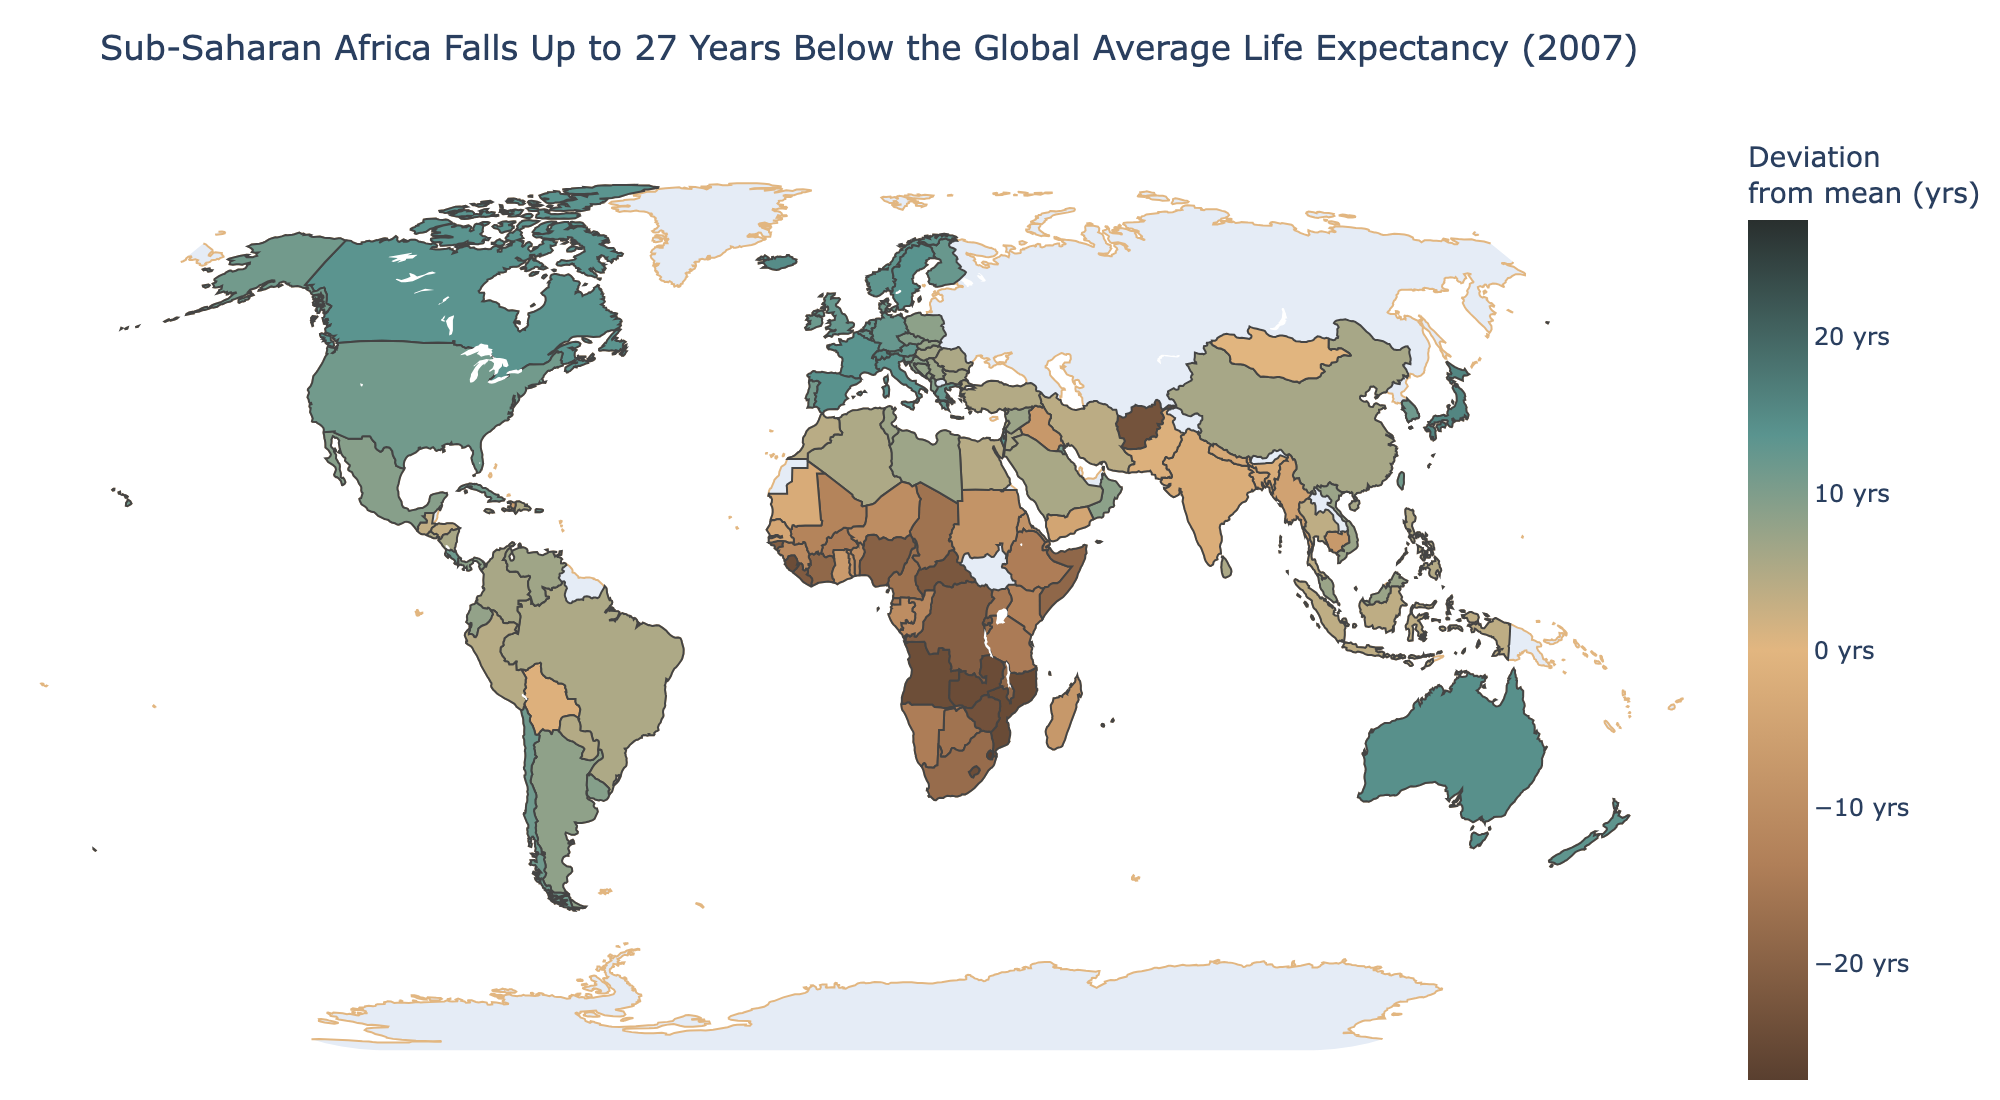

In [2]:
# Task 1

PATINA_DIVERGING = [
    [0.00, "#593F2F"],
    [0.25, "#B07F58"],
    [0.50, "#E2B680"],
    [0.75, "#5A948F"],
    [1.00, "#292F2E"],
]

# Load and filter Gapminder to 2007
gm_2007 = px.data.gapminder().query("year == 2007").copy()

# Compute deviation from global mean life expectancy
global_mean = gm_2007["lifeExp"].mean() 
gm_2007["lifeExp_deviation"] = gm_2007["lifeExp"] - global_mean

fig1 = px.choropleth(
    gm_2007,
    locations="iso_alpha",         
    color="lifeExp_deviation",     
    hover_name="country",
    hover_data={
        "lifeExp": True,           
        "lifeExp_deviation": ":.1f",
        "iso_alpha": False,         
    },
    color_continuous_scale=PATINA_DIVERGING,
    color_continuous_midpoint=0,    
    labels={
        "lifeExp": "Life expectancy (yrs)",
        "lifeExp_deviation": "Deviation from world avg (yrs)",
    },
    title="Sub-Saharan Africa Falls Up to 27 Years Below the Global Average Life Expectancy (2007)",
)

fig1.update_layout(
    coloraxis_colorbar=dict(
        title="Deviation<br>from mean (yrs)",
        ticksuffix=" yrs",
    ),
    geo=dict(showframe=False, showcoastlines=True, coastlinecolor="#E2B680",
             projection_type="natural earth"),
    paper_bgcolor="rgba(0,0,0,0)",
    margin=dict(t=60, l=0, r=0, b=0),
)

# Display as static PNG — much smaller than interactive HTML
from IPython.display import Image, display
display(Image(fig1.to_image(format='png', width=1000, height=550, scale=2)))


In [3]:
# Task 2
import urllib.request

GEOJSON_URL = (
    "https://raw.githubusercontent.com/datasets/geo-countries/"
    "master/data/countries.geojson"
)
with urllib.request.urlopen(GEOJSON_URL) as response:
    countries_geojson = json.loads(response.read())

# Inspect properties to identify featureidkey
print("GeoJSON properties for first feature:")
print(countries_geojson["features"][0]["properties"])

GeoJSON properties for first feature:
{'name': 'Indonesia', 'ISO3166-1-Alpha-3': 'IDN', 'ISO3166-1-Alpha-2': 'ID'}


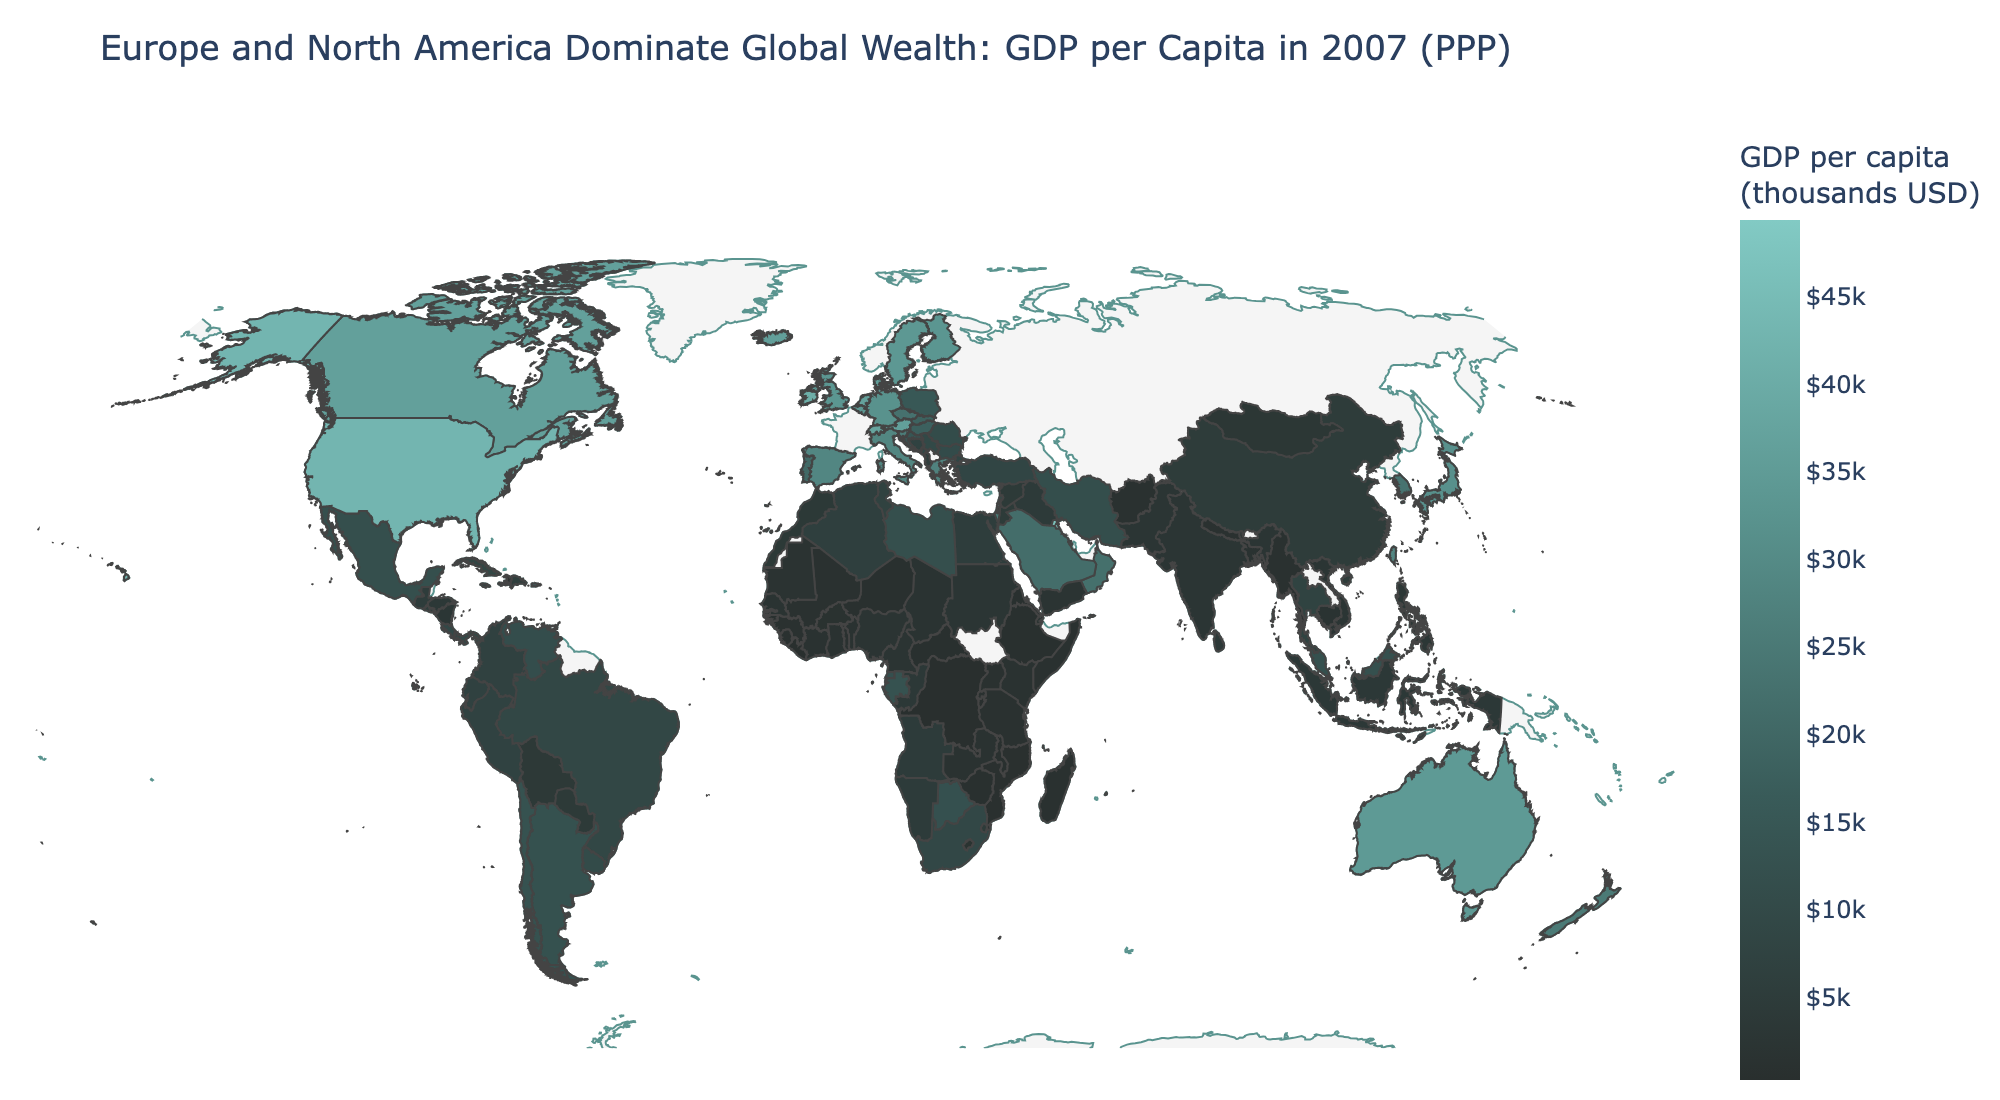

In [4]:
# ── 2. Prepare data ──────────────────────────────────────────────────────────
gdp_2007 = (
    px.data.gapminder()
    .query("year == 2007")[["country", "iso_alpha", "gdpPercap", "continent"]]
    .copy()
)
gdp_2007["gdpPercap_k"] = gdp_2007["gdpPercap"] / 1000  

PATINA_SEQUENTIAL = [
    [0.00, "#292F2E"],  
    [0.33, "#395B59"],  
    [0.66, "#5A948F"],  
    [1.00, "#82CAC4"],  
]

fig2 = px.choropleth(
    gdp_2007,
    geojson=countries_geojson,
    locations="iso_alpha",
    featureidkey="properties.ISO3166-1-Alpha-3",  
    color="gdpPercap_k",
    hover_name="country",
    hover_data={
        "gdpPercap_k": ":.1f",
        "continent": True,
        "iso_alpha": False,
    },
    color_continuous_scale=PATINA_SEQUENTIAL,
    labels={
        "gdpPercap_k": "GDP per capita (k USD, PPP)",
        "continent": "Continent",
    },
    title="Europe and North America Dominate Global Wealth: GDP per Capita in 2007 (PPP)",
)

fig2.update_geos(
    fitbounds="locations",
    visible=False,
    showcoastlines=True,
    coastlinecolor="#5A948F",
    showland=True,
    landcolor="#f5f5f5",
    showocean=True,
    oceancolor="white",
    projection_type="natural earth",
)

fig2.update_layout(
    coloraxis_colorbar=dict(
        title="GDP per capita<br>(thousands USD)",
        tickprefix="$",
        ticksuffix="k",
    ),
    paper_bgcolor="rgba(0,0,0,0)",
    margin=dict(t=60, l=0, r=0, b=0),
)

# Display as static PNG — much smaller than interactive HTML
from IPython.display import Image, display
display(Image(fig2.to_image(format='png', width=1000, height=550, scale=2)))